## Flight Fare Prediction

<img src="https://img.freepik.com/free-photo/jumbo-jet-flying-sky_23-2150895687.jpg" height="100">

## Project Type

Supervised Machine Learning - Regression

## Problem Description

The goal of this project is to predict flight ticket prices using machine learning based on features such as airline, route, duration, stops, and timing, helping users make better booking decisions.

## Data Preprocessing

Date handling 

Time extraction

Duration conversion

Encoding 

## Codes

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load data
df= pd.read_csv("Flight_Fare.csv")
df.head(5)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR ? DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU ? IXR ? BBI ? BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL ? LKO ? BOM ? COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU ? NAG ? BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR ? NAG ? DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [3]:
df.shape

(10683, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [5]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [6]:
# Check missing values
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [7]:
df.dropna(inplace=True)

In [8]:
# Check columns
print(df.columns)

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')


In [9]:
df['Airline'].value_counts()

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1751
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

In [10]:
df['Source'].value_counts()

Source
Delhi       4536
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64

In [11]:
df['Destination'].value_counts()

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

In [12]:
# Date
df['Journey_day'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.day
df['Journey_month'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.month
df.head(2)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR ? DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3
1,Air India,1/05/2019,Kolkata,Banglore,CCU ? IXR ? BBI ? BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5


In [13]:
df.drop('Date_of_Journey', axis=1, inplace=True)

Already represented in Source + Destination + Stops

In [14]:
#drop unnecessary
df.drop('Route', axis=1, inplace=True)

In [15]:
# Departure Time
df['Dep_hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute


In [16]:
df.head(2)

,Airline,Source,Destination,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hour,Dep_min
0,IndiGo,Banglore,New Delhi,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20
1,Air India,Kolkata,Banglore,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,5,50


In [17]:
df.drop('Dep_Time', axis=1, inplace=True)

In [18]:
# Arrival Time
df['Arrival_Time'] = df['Arrival_Time'].apply(lambda x: x.split(' ')[0])

df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arrival_min'] = pd.to_datetime(df['Arrival_Time']).dt.minute
df.head(2)

,Airline,Source,Destination,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,01:10,2h 50m,non-stop,No info,3897,24,3,22,20,1,10
1,Air India,Kolkata,Banglore,13:15,7h 25m,2 stops,No info,7662,1,5,5,50,13,15


In [19]:
df.drop('Arrival_Time', axis=1, inplace=True)

In [20]:
# Duration
duration = df['Duration'].str.split()

df['Duration_hour'] = duration.apply(lambda x: int(x[0][:-1]))

df['Duration_min'] = duration.apply(lambda x: int(x[1][:-1]) if len(x) > 1 else 0)

df.drop('Duration', axis=1, inplace=True)

In [21]:
df.head(2)

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_hour,Duration_min
0,IndiGo,Banglore,New Delhi,non-stop,No info,3897,24,3,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,2 stops,No info,7662,1,5,5,50,13,15,7,25


In [22]:
# Total Stops
df['Total_Stops'].value_counts()

Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [23]:
df['Total_Stops'] = df['Total_Stops'].replace({
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
})

In [24]:
df['Additional_Info'].value_counts()

Additional_Info
No info                         8344
In-flight meal not included     1982
No check-in baggage included     320
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [25]:
# Drop unnecessary
df.drop('Additional_Info', axis=1, inplace=True)

##  Important Insights 


1. Stops vs Price
More stops → cheaper flights

2. Duration vs Price
Longer flights → usually cheaper

3. Airline Impact
Jet Airways → expensive
IndiGo → budget-friendly

## Univariate

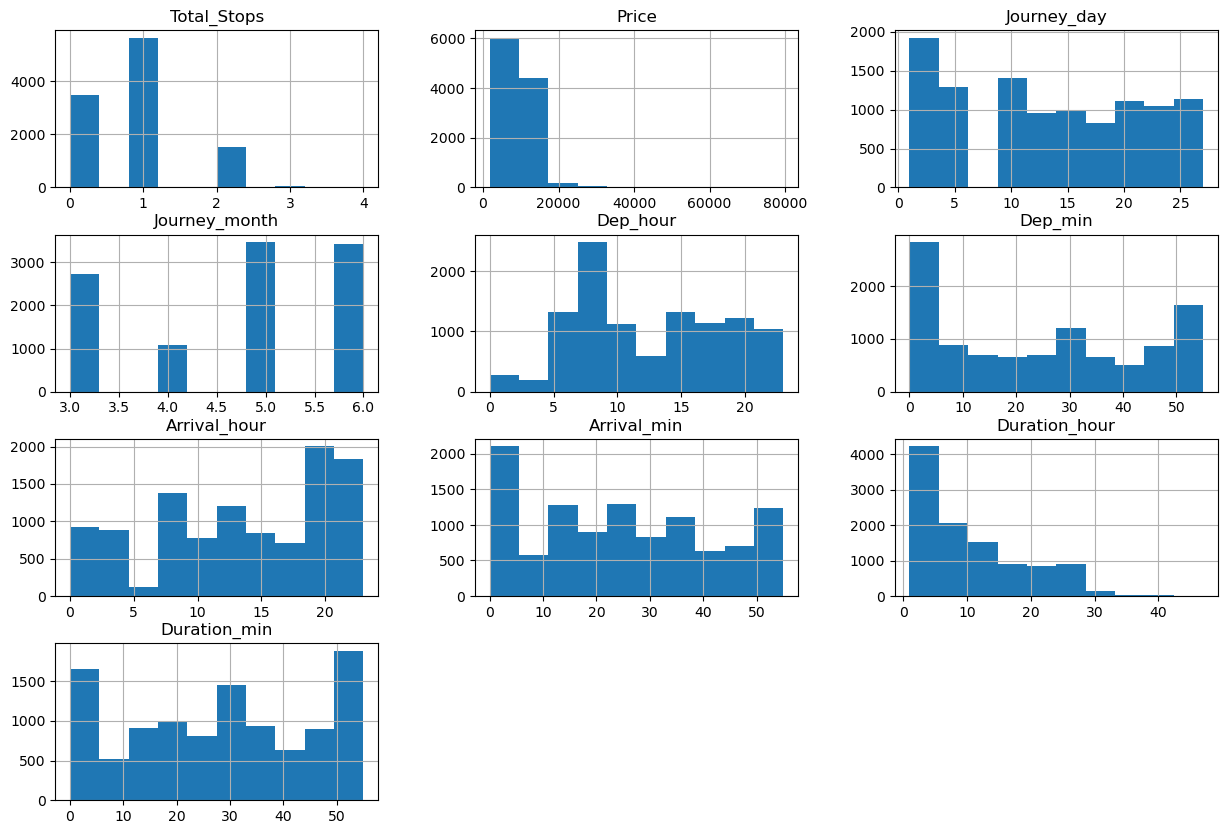

In [26]:
df.hist(figsize=(15,10))
plt.show()

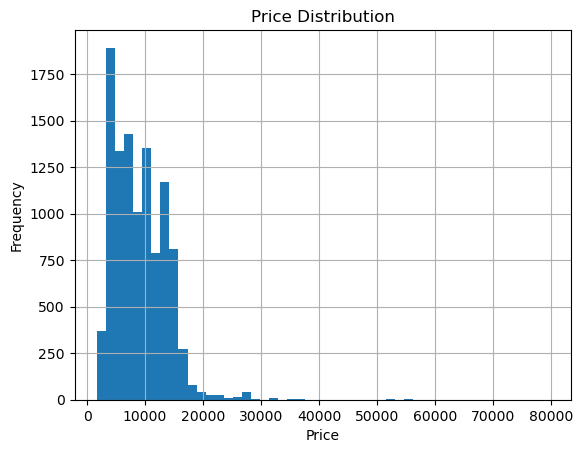

In [27]:
import matplotlib.pyplot as plt
df['Price'].hist(bins=50)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

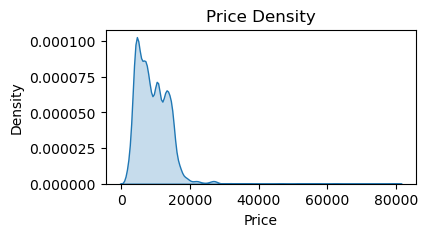

In [28]:
import seaborn as sns
plt.figure(figsize=(4,2))
sns.kdeplot(df['Price'], fill=True)
plt.title("Price Density")
plt.show()

## Histograms and KDE plots were used for numerical variables

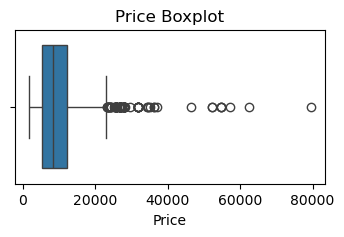

In [29]:
plt.figure(figsize=(4,2))
sns.boxplot(x=df['Price'])
plt.title("Price Boxplot")
plt.show()

## The distribution of the price variable is right-skewed, indicating that while most flight fares fall within a lower range, a small number of observations have significantly higher values. These high-value outliers may correspond to premium services, last-minute bookings, or high-demand routes.

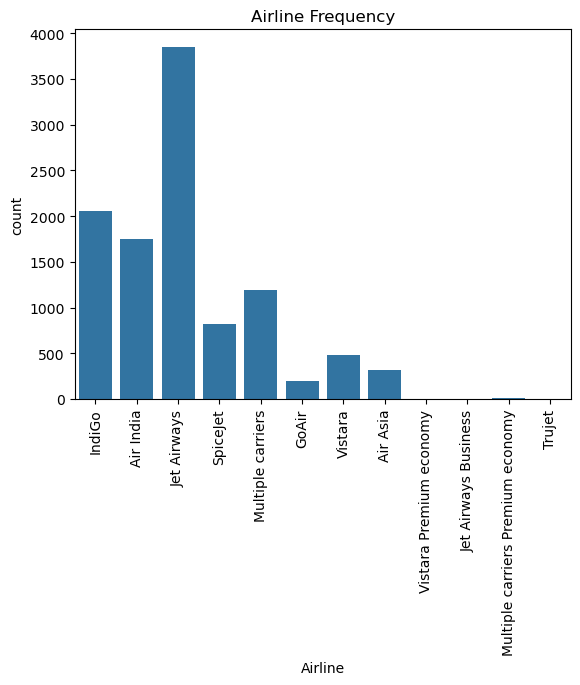

In [30]:
sns.countplot(x='Airline', data=df)
plt.xticks(rotation=90)
plt.title("Airline Frequency")
plt.show()

## count plots were used for categorical features

## Bivariate

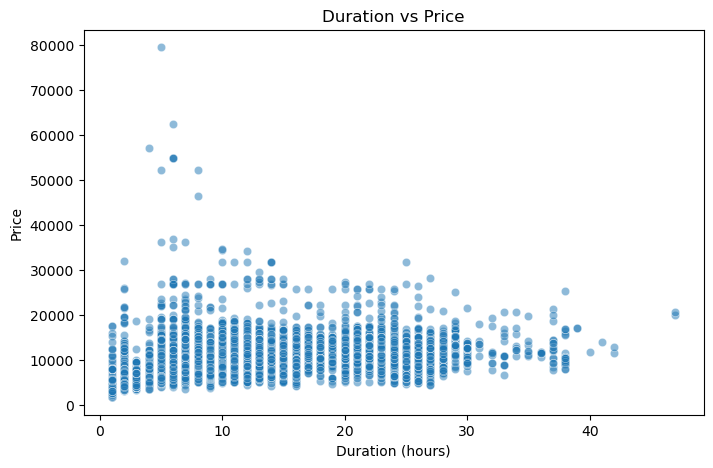

In [31]:

plt.figure(figsize=(8,5))
sns.scatterplot(x='Duration_hour', y='Price', data=df, alpha=0.5)
plt.title("Duration vs Price")
plt.xlabel("Duration (hours)")
plt.ylabel("Price")
plt.show()

## Scatter plots showed a positive relationship between duration and price.

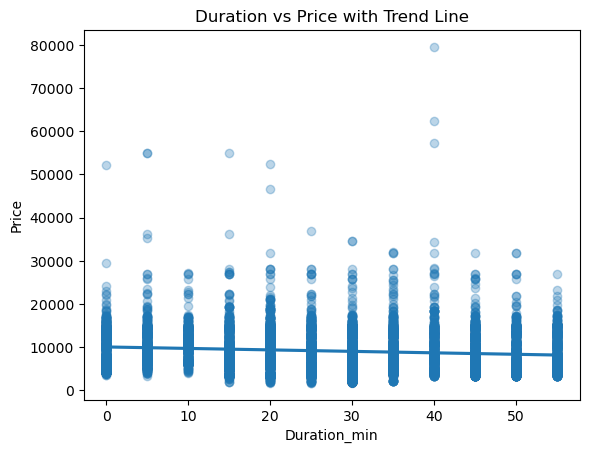

In [32]:
sns.regplot(x='Duration_min', y='Price', data=df, scatter_kws={'alpha':0.3})
plt.title("Duration vs Price with Trend Line")
plt.show()

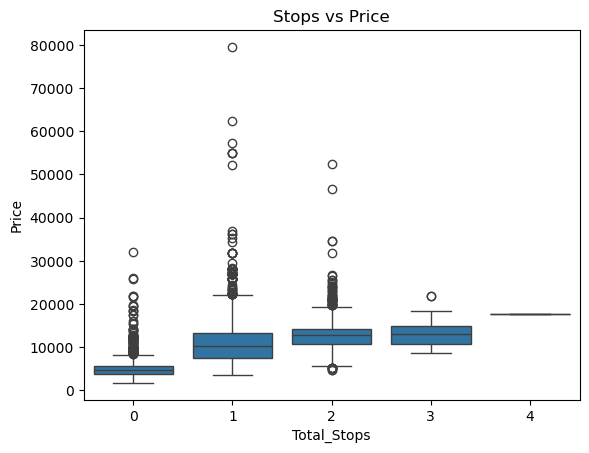

In [33]:
sns.boxplot(x='Total_Stops', y='Price', data=df)
plt.title("Stops vs Price")
plt.show()

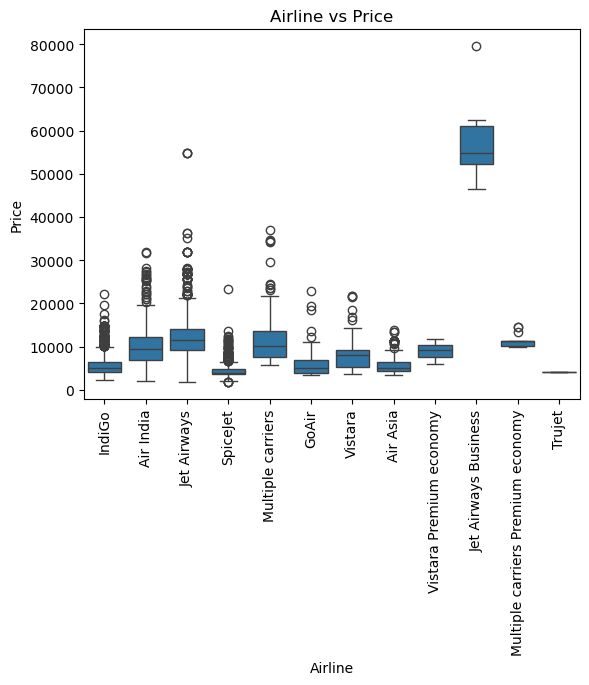

In [34]:
sns.boxplot(x='Airline', y='Price', data=df)
plt.xticks(rotation=90)
plt.title("Airline vs Price")
plt.show()

## Box plots revealed that airline type and number of stops significantly impact ticket prices

## Onehot Encoding

In [35]:
df = pd.get_dummies(df, columns=['Airline', 'Source', 'Destination'], drop_first=True)

## TRAIN TEST SPLIT

In [36]:
# =========================
# 🔹 TRAIN TEST SPLIT
# =========================
from sklearn.model_selection import train_test_split

X = df.drop('Price', axis=1)
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Top 10 features with most outliers:
 Index(['Duration_hour', 'Total_Stops', 'Journey_day', 'Dep_hour',
       'Journey_month', 'Dep_min', 'Arrival_hour', 'Arrival_min',
       'Duration_min'],
      dtype='object')


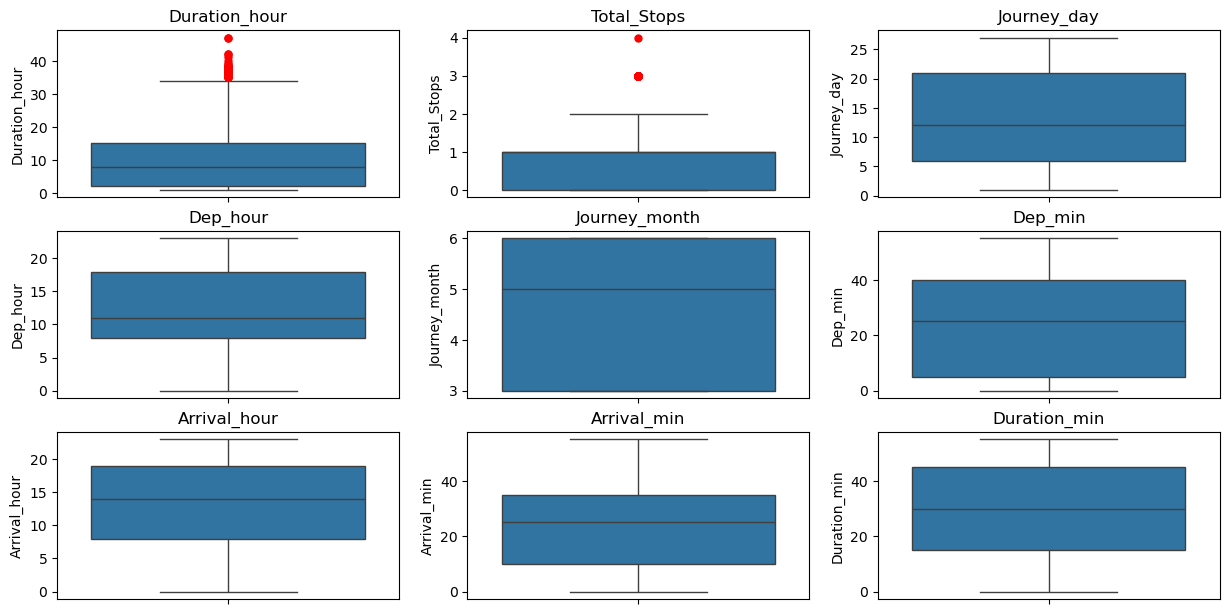

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Detect outliers count for each feature
outlier_counts = {}

for col in X.columns:
    # skip non-numeric columns
    if not np.issubdtype(X[col].dtype, np.number):
        continue
        
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = ((X[col] < lower) | (X[col] > upper)).sum()
    outlier_counts[col] = count

# Step 2: Get top 10 features with most outliers
top_features = (
    pd.Series(outlier_counts)
    .sort_values(ascending=False)
    .head(10)
    .index
)

print("Top 10 features with most outliers:\n", top_features)

# Step 3: Plot boxplots with red outliers
plt.figure(figsize=(15,10))

for i, col in enumerate(top_features):
    plt.subplot(4, 3, i+1)
    
    sns.boxplot(
        y=X[col],
        flierprops=dict(
            marker='o',
            markerfacecolor='red',
            markeredgecolor='red',
            markersize=5
        )
    )
    
    plt.title(col)

plt.show()

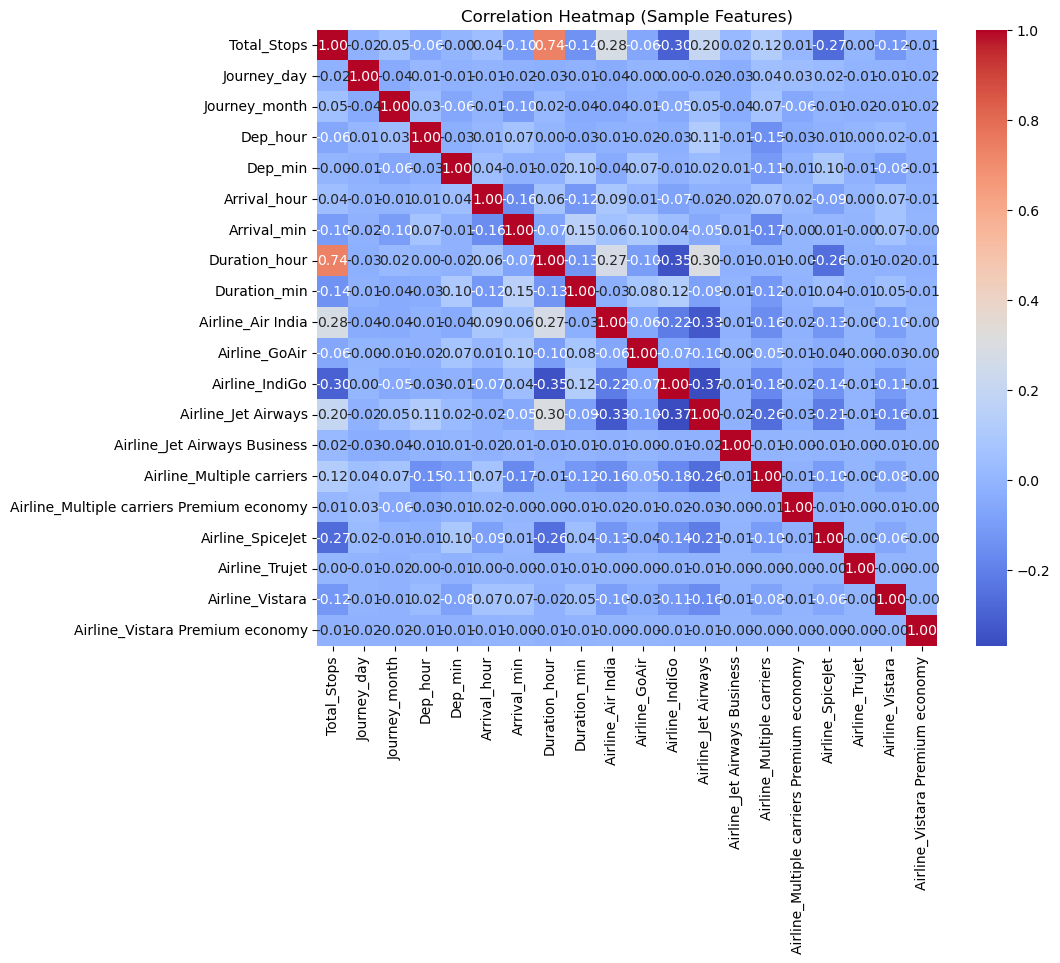

In [38]:
corr = X_train.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr.iloc[:20, :20], cmap="coolwarm",annot=True,
            fmt=".2f")
plt.title("Correlation Heatmap (Sample Features)")
plt.show()

## “Some features like Source and Destination showed perfect correlation because certain routes are fixed in the dataset. This creates multicollinearity, but since I used tree-based models like XGBoost, it did not negatively impact performance.”

## Model Building
1.Linear Regression

2.Random Forest

3.XGboost

In [39]:
# =========================
# 🔹BASELINE  MODELS
# =========================
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

lr = LinearRegression()
rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42)
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6)

# Train
lr.fit(X_train, y_train)
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)

# =========================
# 🔹 EVALUATION FUNCTION
# =========================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model):
    pred = model.predict(X_test)
    return [
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    ]

# =========================
# 🔹 RESULTS
# =========================
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [evaluate(lr)[0], evaluate(rf)[0], evaluate(xgb)[0]],
    'RMSE': [evaluate(lr)[1], evaluate(rf)[1], evaluate(xgb)[1]],
    'R2': [evaluate(lr)[2], evaluate(rf)[2], evaluate(xgb)[2]]
})

print(results)

               Model          MAE         RMSE        R2
0  Linear Regression  1972.924159  2863.982587  0.619591
1      Random Forest  1183.414478  1998.547738  0.814758
2            XGBoost  1191.319580  1830.034699  0.844680


## Hyperparameters for XGBoost

In [40]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

xgb = XGBRegressor(random_state=42)

params = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 6, 8],
    'subsample': [0.6, 0.8, 1],
    'colsample_bytree': [0.6, 0.8, 1]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=params,
    n_iter=10,  # increase to 20 if time allows
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=2,
    random_state=42
)

random_search.fit(X_train, y_train)
# After Tuning
best_model = random_search.best_estimator_

pred = best_model.predict(X_test)

from sklearn.metrics import r2_score
print("Tuned R2:", r2_score(y_test, pred))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Tuned R2: 0.8595683574676514


## Model Comparision

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    
    return mae, rmse, r2



In [42]:
models = {
    "Linear Regression": lr,
    "Random Forest": rf,
    "XGBoost (Base)": xgb,
    "XGBoost (Tuned)": best_model
}


In [43]:
results = []

for name, model in models.items():
    
    # Ensure model is trained
    model.fit(X_train, y_train)
    
    mae, rmse, r2 = evaluate_model(model, X_test, y_test)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='R2 Score', ascending=False)

print(results_df)

               Model          MAE         RMSE  R2 Score
3    XGBoost (Tuned)  1113.857910  1740.113430  0.859568
2     XGBoost (Base)  1126.825562  1804.915233  0.848914
1      Random Forest  1183.414478  1998.547738  0.814758
0  Linear Regression  1972.924159  2863.982587  0.619591


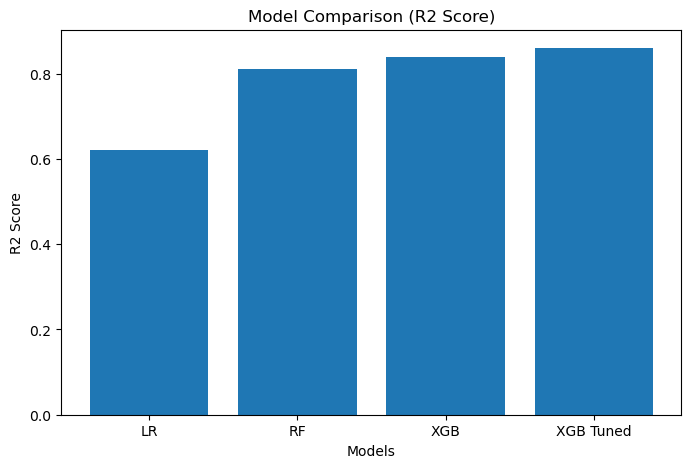

In [44]:
import matplotlib.pyplot as plt

models = ['LR', 'RF', 'XGB', 'XGB Tuned']
r2_scores = [0.62, 0.81, 0.84, 0.86]

plt.figure(figsize=(8,5))
plt.bar(models, r2_scores)
plt.title("Model Comparison (R2 Score)")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.show()

## Feature Importance Chart (XGBoost)

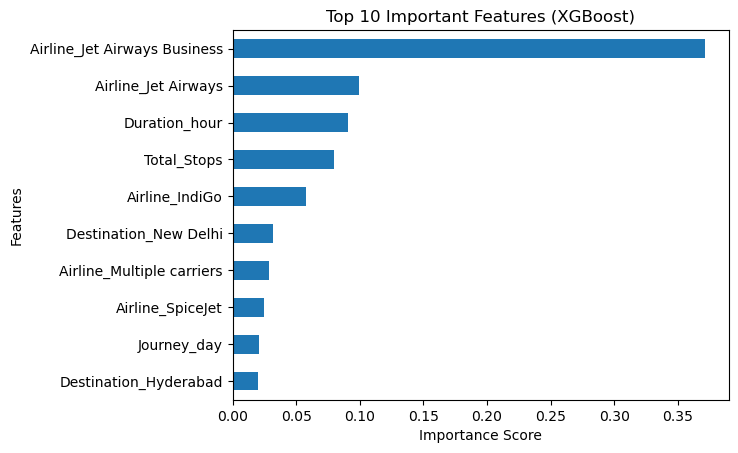

In [45]:
import pandas as pd

# Get importance
importances = best_model.feature_importances_

# Convert to series
feat_imp = pd.Series(importances, index=X_train.columns)

# Sort descending and take top 10
feat_imp_top = feat_imp.sort_values(ascending=False).head(10)

# Plot (reverse for proper barh display)
feat_imp_top[::-1].plot(kind='barh')

plt.title("Top 10 Important Features (XGBoost)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

## 1. Airline_Jet Airways Business (Highest Importance)

This feature has the highest importance, indicating that premium airline services significantly impact ticket prices. Business-class flights are typically much more expensive due to higher service quality and comfort.

## 2. Airline_Jet Airways

This suggests that the airline itself plays a major role in pricing. Different airlines have different pricing strategies based on brand value, demand, and service offerings.

## 3. Duration_hour

Flight duration is a strong predictor of price. Longer flights generally cost more due to higher fuel consumption and operational costs.

## 4. Total_Stops

The number of stops significantly affects price. Non-stop flights tend to be more expensive, while flights with multiple stops are usually cheaper.

## 5. Airline_IndiGo / Airline_SpiceJet / Airline_Multiple carriers

These features indicate that budget and mid-range airlines influence pricing differently. Low-cost carriers often offer cheaper tickets compared to premium airlines.

## 6. Destination_New Delhi / Destination_Hyderabad

Destination impacts pricing due to route demand, airport traffic, and popularity. High-demand routes generally have higher prices.

## 7. Journey_day

This shows that the day of travel has some influence on price, possibly due to demand variations (weekends, holidays, etc.).

In [46]:
# XGBoost
xgb_imp = pd.Series(best_model.feature_importances_, index=X_train.columns)

# Random Forest
rf_imp = pd.Series(rf.feature_importances_, index=X_train.columns)

feat_imp_df = pd.DataFrame({
    'XGBoost': xgb_imp,
    'RandomForest': rf_imp
})

top_features = feat_imp_df.mean(axis=1).nlargest(10).index
feat_imp_top = feat_imp_df.loc[top_features]

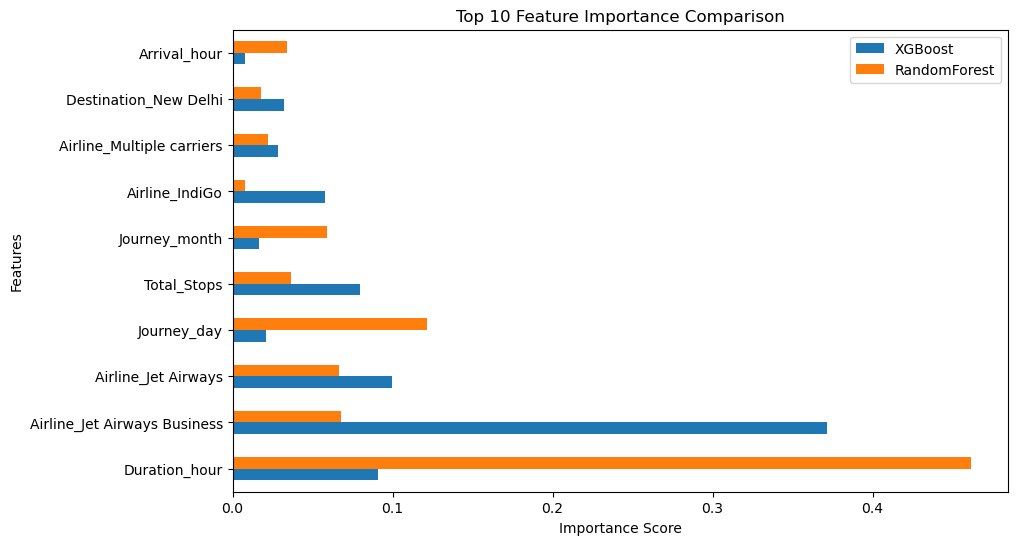

In [47]:
feat_imp_top.plot(kind='barh', figsize=(10,6))

plt.title("Top 10 Feature Importance Comparison")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.legend()
plt.show()

##  Both models agree on core features like airline, duration, and stops, Random Forest focuses more on time-related features, whereas XGBoost emphasizes airline-specific pricing patterns.

# Actual vs Predicted Plot

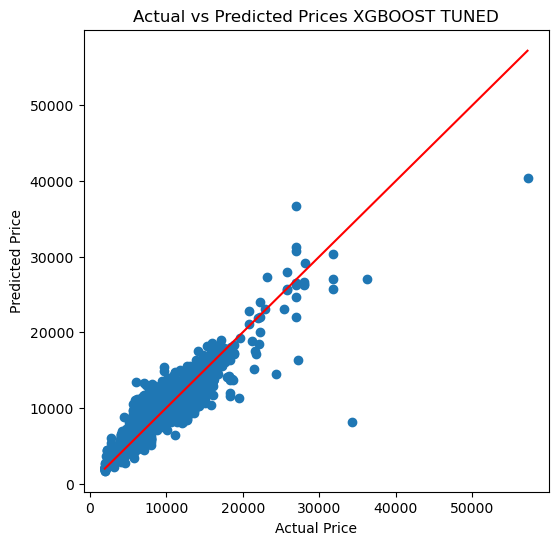

In [48]:
import matplotlib.pyplot as plt

# Predictions
y_pred = best_model.predict(X_test)

# Plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices XGBOOST TUNED")

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red')

plt.show()

In [64]:
pip install shap

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/555.9 kB ? eta -:--:--
   ------------------------------------- -- 524.3/555.9 kB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 555.9/555.9 kB 2.1 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ----------------

In [49]:
import shap

# Initialize explainer
explainer = shap.Explainer(best_model)

# Calculate SHAP values
shap_values = explainer(X_test)

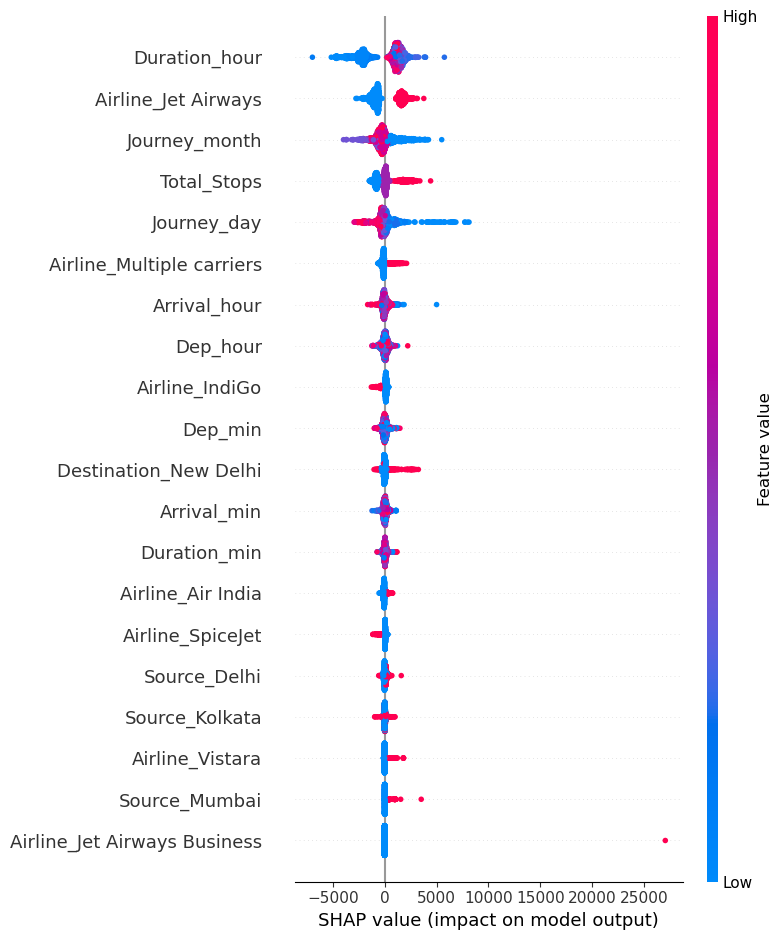

In [50]:
shap.summary_plot(shap_values, X_test)

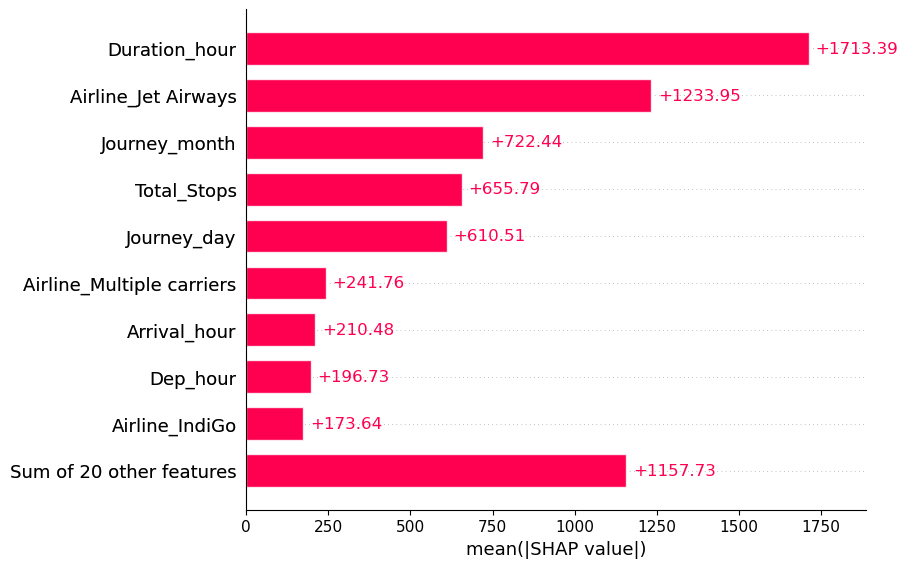

In [51]:
shap.plots.bar(shap_values)

## SHAP analysis was performed to interpret the model’s predictions. The results show that duration, airline type, and number of stops are the most influential features affecting flight prices. Longer durations and premium airlines significantly increase prices, while flights with more stops tend to reduce prices. Additionally, seasonal and day-based variations also impact pricing. These findings align with real-world factors such as demand, service quality, and travel convenience.

## Best Model

In [52]:
best = results_df.iloc[0]
print("Best Model:", best['Model'])
print("Best R2 Score:", best['R2 Score'])

Best Model: XGBoost (Tuned)
Best R2 Score: 0.8595683574676514


## Conclusion

“After applying hyperparameter tuning using RandomizedSearchCV, the XGBoost model improved from an R² score of 0.84 to 0.86. This demonstrates better generalization and reduced prediction error, making it the final selected model for flight fare prediction.”

## Business Insight

“The final model predicts flight prices with high accuracy and can help users make cost-effective travel decisions while supporting dynamic pricing strategies.”